# 07 · Explanations: TreeSHAP reason families and their stability

**FinGuard AI, Phase 2.** Reads `artifacts/phase2/shap/families.pkl` (pipeline stage `shap`).

1. TreeSHAP values come from LightGBM itself (`pred_contrib=True`); check that they add up
   to the model score (local accuracy).
2. Where the model's attribution sits, by reason family (readable vs anonymized).
3. Reason cards for alerted test transactions: the top 5 positive families, each worded by a
   fixed template that states only what the data contains.
4. Stability: do 5 retrains with other random seeds give the same top-5 families? (target >= 0.6)

About 96% of the columns are anonymized, so explanations are given per **family**, and
anonymized families say that their meaning is not disclosed.

In [1]:
import sys, pathlib, json, pickle
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config, phase2
from finguard.evaluation import figures as F
from finguard.evaluation import metrics as M
from finguard.explain import reasons as R
from finguard.models import calibration as C
from finguard.models import dataset

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 200)
T = config.TABLE_DIR
codes = phase2.selected_codes()
fs = dataset.load("main", codes)
with open(phase2.ART / "shap" / "families.pkl", "rb") as f:
    S = pickle.load(f)
cols = S["columns"]
alert_idx, sample_idx = S["alert_idx"], S["sample_idx"]
bands = S["bands"]
band_of_alert = bands.assign(phase2.load_preds(f"lgbm_{codes}")["test_raw"][np.searchsorted(np.flatnonzero(fs.masks["test"]), alert_idx)])
print(f"alerted test transactions (High + Medium): {len(alert_idx):,} | random test sample: {len(sample_idx):,}")
print(f"local accuracy: max |sum(SHAP) + bias - raw score| = {S['local_accuracy_max_abs_error']:.2e} (log-odds)")

alerted test transactions (High + Medium): 4,797 | random test sample: 5,000
local accuracy: max |sum(SHAP) + bias - raw score| = 1.90e-09 (log-odds)


## 1. Where the attribution sits
Mean |SHAP| per family on 5,000 random test transactions, as a share of the total.

,family,label,share,anonymized
4,card,Card attributes,0.140639,False
11,timedelta_D,Anonymized time-delta features (D1-D15),0.134564,True
13,vesta_V,Vesta engineered features (V1-V339),0.131221,True
10,counting_C,Anonymized counting features (C1-C14),0.131029,True
2,amount,Amount,0.093900,False
5,address,Address and distance codes,0.066143,False
6,email,Email domains,0.063355,False
12,match_M,Match flags (M1-M9),0.038635,True
14,completeness,Data completeness,0.037373,False
8,identity_masked,Anonymized identity signals (id_XX),0.033733,True


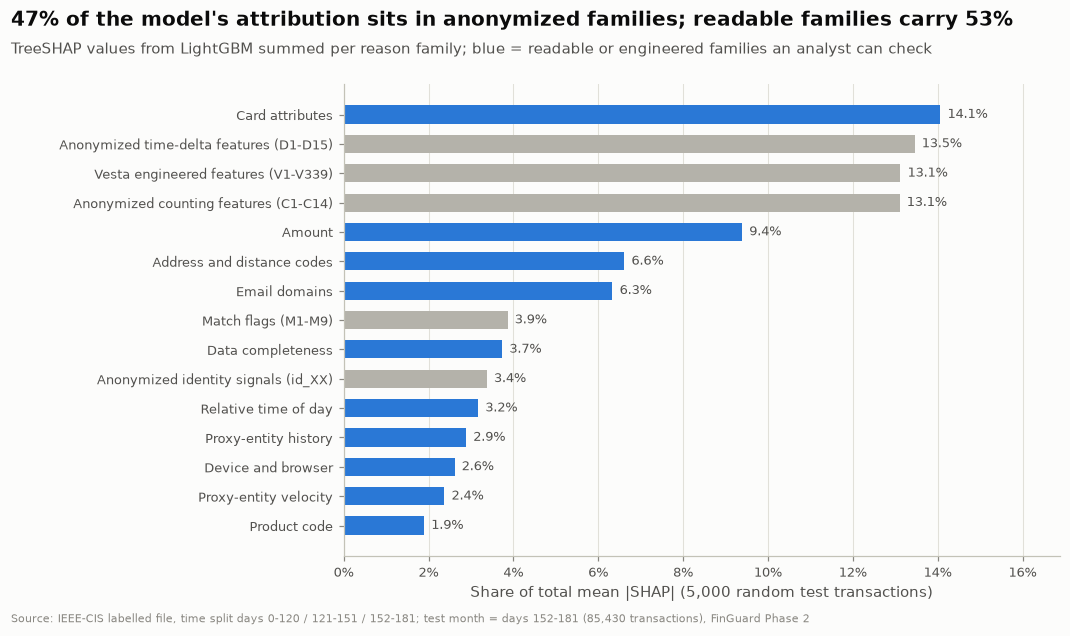

In [2]:
fam_abs = S["main_sample"].abs().mean()
imp = pd.DataFrame({"family": fam_abs.index, "label": [R.FAMILY_LABEL[f] for f in fam_abs.index],
                    "share": (fam_abs / fam_abs.sum()).to_numpy(),
                    "anonymized": [f in R.ANONYMIZED for f in fam_abs.index]}).sort_values("share", ascending=False)
imp.to_csv(T / "phase2_family_importance.csv", index=False)
fig = F.fig23_family_importance(imp.reset_index(drop=True))
imp

In [3]:
feat = pd.DataFrame({"feature": cols, "mean_abs_shap": S["main_sample_abs_by_feature"]})
feat["family"] = [R.family(c) for c in feat.feature]
feat["anonymized"] = feat.family.isin(R.ANONYMIZED)
feat = feat.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
feat.to_csv(T / "phase2_feature_shap.csv", index=False)
print("top 20 single features (for reference; reasons are given per family):")
feat.head(20)

top 20 single features (for reference; reasons are given per family):


,feature,mean_abs_shap,family,anonymized
0,C13,0.570316,counting_C,True
1,TransactionAmt,0.406279,amount,False
2,D1n,0.278838,timedelta_D,True
3,C1,0.250881,counting_C,True
4,freq_card1,0.223983,card,False
5,C14,0.219266,counting_C,True
6,card6,0.208967,card,False
7,P_emaildomain,0.206929,email,False
8,D4n,0.183749,timedelta_D,True
9,freq_card2,0.183655,card,False


## 2. Reason cards
For each alerted transaction: the five families that pushed the score up most. Values come
from the transaction itself (categories decoded with the training-window vocabulary).

In [4]:
fam_alert = S["main_alert"]
top5 = R.top_families(fam_alert, k=5)
readable = R.decode(pd.DataFrame(np.asarray(fs.X[alert_idx]), columns=fs.columns), fs.builder)
raw = phase2.load_preds(f"lgbm_{codes}")
iso = C.fit_isotonic(raw["valid_raw"], fs.y[fs.masks["valid"]])
score_alert = fam_alert.sum(axis=1).to_numpy() + S["expected_value"]
p_alert = iso.predict(score_alert)

def card(i):
    head = (f"TransactionID {fs.transaction_id[alert_idx[i]]} | band {band_of_alert[i]} | calibrated fraud probability "
            f"{C.display_probability(p_alert[i])} | label (not shown to the model) {'fraud' if fs.y[alert_idx[i]] else 'legitimate'}")
    return head + "\n" + "\n".join(f"  {k + 1}. {line}" for k, line in enumerate(R.reason_lines(fam_alert.iloc[i], readable.iloc[i])))

rs = np.random.RandomState(7)
examples = list(rs.choice(np.flatnonzero(band_of_alert == "High"), 3, replace=False)) + \
           list(rs.choice(np.flatnonzero(band_of_alert == "Medium"), 2, replace=False))
for i in examples:
    print(card(i), "\n")

TransactionID 3550979 | band High | calibrated fraud probability 91% | label (not shown to the model) fraud
  1. Anonymized counting features (C1-C14): meaning not disclosed by the data provider. [+6.81 log-odds]
  2. Vesta engineered features (V1-V339): meaning not disclosed by the data provider. [+4.89 log-odds]
  3. Anonymized identity signals (id_XX): meaning not disclosed by the data provider. [+0.77 log-odds]
  4. Card attributes: network visa, type credit; card1 code seen 76 time(s) in the training window (card codes are undisclosed). [+0.67 log-odds]
  5. Address and distance codes: billing-region code, country code, distance field not given (undisclosed codes). [+0.53 log-odds] 

TransactionID 3548165 | band High | calibrated fraud probability >99% | label (not shown to the model) fraud
  1. Vesta engineered features (V1-V339): meaning not disclosed by the data provider. [+7.30 log-odds]
  2. Anonymized counting features (C1-C14): meaning not disclosed by the data provider. [+

In [5]:
first = pd.Series([t[0] if t else "none" for t in top5])
any_readable = np.mean([any(f not in R.ANONYMIZED for f in t) for t in top5])
summary = {"alerts": len(top5),
           "share_with_5_positive_families": float(np.mean([len(t) == 5 for t in top5])),
           "share_top1_family_readable": float((~first.isin(list(R.ANONYMIZED) + ["none"])).mean()),
           "share_with_a_readable_family_in_top5": float(any_readable)}
freq = pd.Series([f for t in top5 for f in t]).value_counts() / len(top5)
freq_t = pd.DataFrame({"family": freq.index, "label": [R.FAMILY_LABEL[f] for f in freq.index], "share_in_top5": freq.to_numpy(),
                       "anonymized": [f in R.ANONYMIZED for f in freq.index]})
print(summary)
freq_t

{'alerts': 4797, 'share_with_5_positive_families': 1.0, 'share_top1_family_readable': 0.19470502397331665, 'share_with_a_readable_family_in_top5': 1.0}


,family,label,share_in_top5,anonymized
0,vesta_V,Vesta engineered features (V1-V339),0.828434,True
1,timedelta_D,Anonymized time-delta features (D1-D15),0.797373,True
2,counting_C,Anonymized counting features (C1-C14),0.782989,True
3,card,Card attributes,0.648947,False
4,email,Email domains,0.461955,False
5,address,Address and distance codes,0.420263,False
6,amount,Amount,0.400876,False
7,identity_masked,Anonymized identity signals (id_XX),0.213050,True
8,match_M,Match flags (M1-M9),0.129664,True
9,time,Relative time of day,0.095268,False


In [6]:
cards = pd.DataFrame({"TransactionID": fs.transaction_id[alert_idx], "band": band_of_alert, "calibrated_p": p_alert,
                      "label": fs.y[alert_idx], **{f"reason_{k + 1}": [R.FAMILY_LABEL[t[k]] if len(t) > k else "" for t in top5] for k in range(5)}})
cards.to_csv(T / "phase2_reason_cards.csv", index=False)
(T / "phase2_reason_examples.txt").write_text("\n\n".join(card(i) for i in examples))
cards.head()

,TransactionID,band,calibrated_p,label,reason_1,reason_2,reason_3,reason_4,reason_5
0,3492325,High,0.948905,1,Vesta engineered features (V1-V339),Anonymized counting features (C1-C14),Anonymized time-delta features (D1-D15),Card attributes,Anonymized identity signals (id_XX)
1,3492361,Medium,0.827815,1,Vesta engineered features (V1-V339),Anonymized counting features (C1-C14),Anonymized time-delta features (D1-D15),Anonymized identity signals (id_XX),Device and browser
2,3492400,Medium,0.201258,0,Card attributes,Anonymized time-delta features (D1-D15),Address and distance codes,Amount,Vesta engineered features (V1-V339)
3,3492435,Medium,0.337662,0,Anonymized time-delta features (D1-D15),Anonymized counting features (C1-C14),Vesta engineered features (V1-V339),Amount,Address and distance codes
4,3492496,Medium,0.721925,1,Anonymized counting features (C1-C14),Vesta engineered features (V1-V339),Anonymized time-delta features (D1-D15),Anonymized identity signals (id_XX),Email domains


## 3. Stability across 5 retrains
Same training data, same settings, five other random seeds (bagging and feature sampling).
For every alerted transaction: mean pairwise overlap |A ∩ B| / 5 of the top-5 families over
the 10 pairs of retrains. Target from the design review: at least 0.6.

{'mean_pairwise_overlap': 0.9133708567854909,
 'median_pairwise_overlap': 0.9199999999999999,
 'share_transactions_overlap_ge_0.6': 1.0,
 'mean_overlap_retrain_vs_main': 0.9125119866583281,
 'top1_agreement_across_retrains': 0.7750677506775068,
 'target': 0.6}

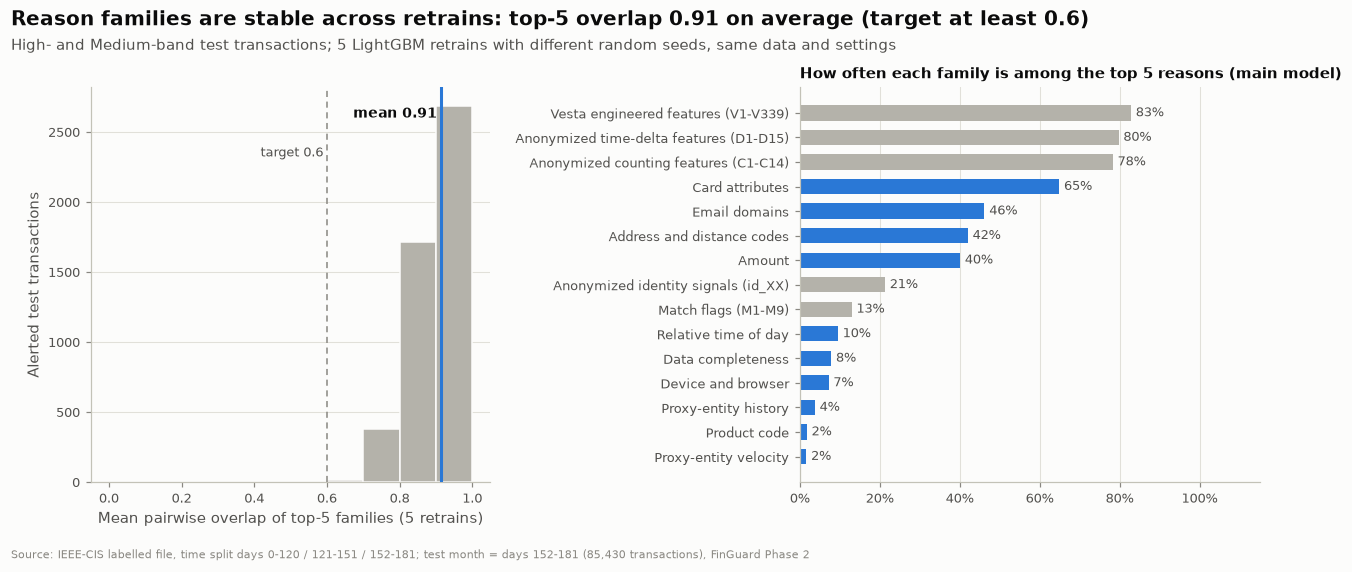

In [7]:
seeds = phase2.SEEDS_RETRAIN
tops = [R.top_families(S[f"seed{s}_alert"], k=5) for s in seeds]
st = R.stability(tops, k=5)
vs_main = np.mean([R.overlap(top5, t).mean() for t in tops])
stab = {"mean_pairwise_overlap": float(st.mean_pairwise_overlap.mean()),
        "median_pairwise_overlap": float(st.mean_pairwise_overlap.median()),
        "share_transactions_overlap_ge_0.6": float((st.mean_pairwise_overlap >= 0.6).mean()),
        "mean_overlap_retrain_vs_main": float(vs_main),
        "top1_agreement_across_retrains": float(np.mean([len({t[i][0] if t[i] else None for t in tops}) == 1 for i in range(len(top5))])),
        "target": 0.6}
fig = F.fig24_reason_stability(st.mean_pairwise_overlap.to_numpy(), freq_t.reset_index(drop=True))
stab

### Do the retrains also agree on the scores?

In [8]:
y_te = fs.y[fs.masks["test"]].astype(int)
seed_rows = [{"model": "main (seed 42)", **M.ranking(y_te, raw["test_raw"])}] + \
            [{"model": f"retrain seed {s}", **M.ranking(y_te, phase2.load_preds(f"retrain_seed{s}")["test_raw"])} for s in seeds]
seed_t = pd.DataFrame(seed_rows).set_index("model")[["pr_auc", "roc_auc", "recall@1%", "recall@5%"]]
spread = seed_t.agg(["mean", "std", "min", "max"])
seed_t.to_csv(T / "phase2_seed_variance.csv")
(T / "phase2_explanations.json").write_text(json.dumps({"local_accuracy_max_abs_error": S["local_accuracy_max_abs_error"],
    "reason_summary": summary, "stability": stab, "seed_spread": spread.to_dict()}, indent=1, default=float))
pd.concat([seed_t, spread])

,pr_auc,roc_auc,recall@1%,recall@5%
main (seed 42),0.580483,0.906831,0.254509,0.623914
retrain seed 1,0.577723,0.906668,0.254843,0.616900
retrain seed 2,0.576606,0.905785,0.256847,0.621576
retrain seed 3,0.577248,0.908068,0.255845,0.618904
retrain seed 4,0.577763,0.907516,0.255511,0.621242
retrain seed 5,0.573368,0.906864,0.255845,0.617234
mean,0.577199,0.906955,0.255567,0.619962
std,0.002298,0.000778,0.000829,0.002750
min,0.573368,0.905785,0.254509,0.616900
max,0.580483,0.908068,0.256847,0.623914


**Reading.** Family-level reasons are what the analyst sees in Phase 3. Anonymized
families are reported honestly as "meaning not disclosed"; the readable and engineered
families (proxy-entity velocity and history, amount, card, email, device, completeness)
carry the explanation an analyst can check against the transaction.